# Standard Deviation Analysis - Predicted vs Filtered Force

This notebook calculates the standard deviation between predicted force and filtered force (FF_EE).

**Formula:**
σ_noise = √(1/N × Σ(x(t) - x^(t))²)

Where:
- x(t) = FF_EE(t) (filtered force)
- x^(t) = predicted_force(t) (predicted force)
- N = total number of samples

**What this measures:**
- The RMS of the difference between filtered and predicted forces
- Higher σ indicates more difference between the two signals
- Lower σ indicates the two signals are more similar


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Load the predictions dataset
data_path = Path('mlp_predictions_dataset.jsonl')

print(f"Loading data from {data_path}...")
data_points = []
with open(data_path, 'r') as f:
    for line in f:
        if line.strip():
            data_points.append(json.loads(line))

print(f"✓ Loaded {len(data_points)} data points")

# Extract the force signals
FF_EE = np.array([dp['FF_EE'] for dp in data_points])  # Shape: (N, 6) - filtered force
predicted_force = np.array([dp['predicted_force'] for dp in data_points])  # Shape: (N, 6) - predicted force

print(f"\nData shapes:")
print(f"  FF_EE (filtered): {FF_EE.shape}")
print(f"  predicted_force: {predicted_force.shape}")

# Calculate sampling frequency
timestamps = np.array([dp['timestamp'] for dp in data_points])
mean_freq = 1.0 / np.mean(np.diff(timestamps))
print(f"\nMean sampling frequency: {mean_freq:.2f} Hz")


Loading data from mlp_predictions_dataset.jsonl...
✓ Loaded 48745 data points

Data shapes:
  FF_EE (filtered): (48745, 6)
  predicted_force: (48745, 6)

Mean sampling frequency: 250.00 Hz


In [2]:
# Calculate the difference between filtered and predicted force
# x(t) = FF_EE(t) (filtered force)
# x^(t) = predicted_force(t) (predicted force)
# Formula: σ = √(1/N × Σ(x(t) - x^(t))²)

print("=" * 80)
print("CALCULATING STANDARD DEVIATION")
print("=" * 80)
print(f"\nFormula: σ = √(1/N × Σ(FF_EE(t) - predicted_force(t))²)")
print(f"Where x(t) = FF_EE (filtered), x^(t) = predicted_force")

# Calculate statistics for each dimension
dim_names = ['Fx', 'Fy', 'Fz', 'Mx', 'My', 'Mz']
results = []

for dim in range(6):
    x_filtered = FF_EE[:, dim]  # x(t) = filtered force
    x_predicted = predicted_force[:, dim]  # x^(t) = predicted force
    
    # Calculate the difference: x(t) - x^(t)
    difference = x_filtered - x_predicted
    
    # Calculate standard deviation using the formula: σ = √(1/N × Σ(x(t) - x^(t))²)
    N = len(difference)
    squared_differences = difference**2
    std_dev = np.sqrt(np.sum(squared_differences) / N)
    
    # Also calculate mean difference for reference
    mean_diff = np.mean(difference)
    
    # Store results
    results.append({
        'dimension': dim_names[dim],
        'mean_difference': mean_diff,
        'std_dev': std_dev,
        'min_difference': np.min(difference),
        'max_difference': np.max(difference),
        'range_difference': np.max(difference) - np.min(difference)
    })
    
    print(f"\n{dim_names[dim]}:")
    print(f"  Standard deviation: {std_dev:.6f}")
    print(f"  Mean difference: {mean_diff:.6f}")
    print(f"  Difference range: [{np.min(difference):.6f}, {np.max(difference):.6f}]")
    print(f"  Range: {np.max(difference) - np.min(difference):.6f}")

std_dev_df = pd.DataFrame(results)
print("\n✓ Standard deviation calculated for all dimensions")


CALCULATING STANDARD DEVIATION

Formula: σ = √(1/N × Σ(FF_EE(t) - predicted_force(t))²)
Where x(t) = FF_EE (filtered), x^(t) = predicted_force

Fx:
  Standard deviation: 0.018410
  Mean difference: 0.006670
  Difference range: [-0.190454, 0.180361]
  Range: 0.370815

Fy:
  Standard deviation: 0.025915
  Mean difference: 0.015757
  Difference range: [-0.194469, 0.221762]
  Range: 0.416231

Fz:
  Standard deviation: 0.020407
  Mean difference: 0.010604
  Difference range: [-0.141490, 0.150485]
  Range: 0.291975

Mx:
  Standard deviation: 0.001622
  Mean difference: -0.000195
  Difference range: [-0.015214, 0.012704]
  Range: 0.027919

My:
  Standard deviation: 0.001554
  Mean difference: -0.000971
  Difference range: [-0.014504, 0.009450]
  Range: 0.023954

Mz:
  Standard deviation: 0.000641
  Mean difference: 0.000099
  Difference range: [-0.006883, 0.005855]
  Range: 0.012738

✓ Standard deviation calculated for all dimensions


In [3]:
# Summary Table
print("\n" + "=" * 80)
print("SUMMARY: STANDARD DEVIATION OF FILTERED vs PREDICTED FORCE")
print("=" * 80)

summary_data = []
for dim in range(6):
    summary_data.append({
        'Dimension': dim_names[dim],
        'Std Dev (σ)': f"{std_dev_df.iloc[dim]['std_dev']:.6f}",
        'Mean Difference': f"{std_dev_df.iloc[dim]['mean_difference']:.6f}",
        'Min Difference': f"{std_dev_df.iloc[dim]['min_difference']:.6f}",
        'Max Difference': f"{std_dev_df.iloc[dim]['max_difference']:.6f}",
        'Range': f"{std_dev_df.iloc[dim]['range_difference']:.6f}"
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Calculate overall statistics
print("\n" + "-" * 80)
print("OVERALL STATISTICS (across all 6 dimensions):")
print("-" * 80)
print(f"Average standard deviation: {std_dev_df['std_dev'].mean():.6f}")
print(f"Min standard deviation: {std_dev_df['std_dev'].min():.6f} ({dim_names[std_dev_df['std_dev'].idxmin()]})")
print(f"Max standard deviation: {std_dev_df['std_dev'].max():.6f} ({dim_names[std_dev_df['std_dev'].idxmax()]})")



SUMMARY: STANDARD DEVIATION OF FILTERED vs PREDICTED FORCE
Dimension Std Dev (σ) Mean Difference Min Difference Max Difference    Range
       Fx    0.018410        0.006670      -0.190454       0.180361 0.370815
       Fy    0.025915        0.015757      -0.194469       0.221762 0.416231
       Fz    0.020407        0.010604      -0.141490       0.150485 0.291975
       Mx    0.001622       -0.000195      -0.015214       0.012704 0.027919
       My    0.001554       -0.000971      -0.014504       0.009450 0.023954
       Mz    0.000641        0.000099      -0.006883       0.005855 0.012738

--------------------------------------------------------------------------------
OVERALL STATISTICS (across all 6 dimensions):
--------------------------------------------------------------------------------
Average standard deviation: 0.011425
Min standard deviation: 0.000641 (Mz)
Max standard deviation: 0.025915 (Fy)


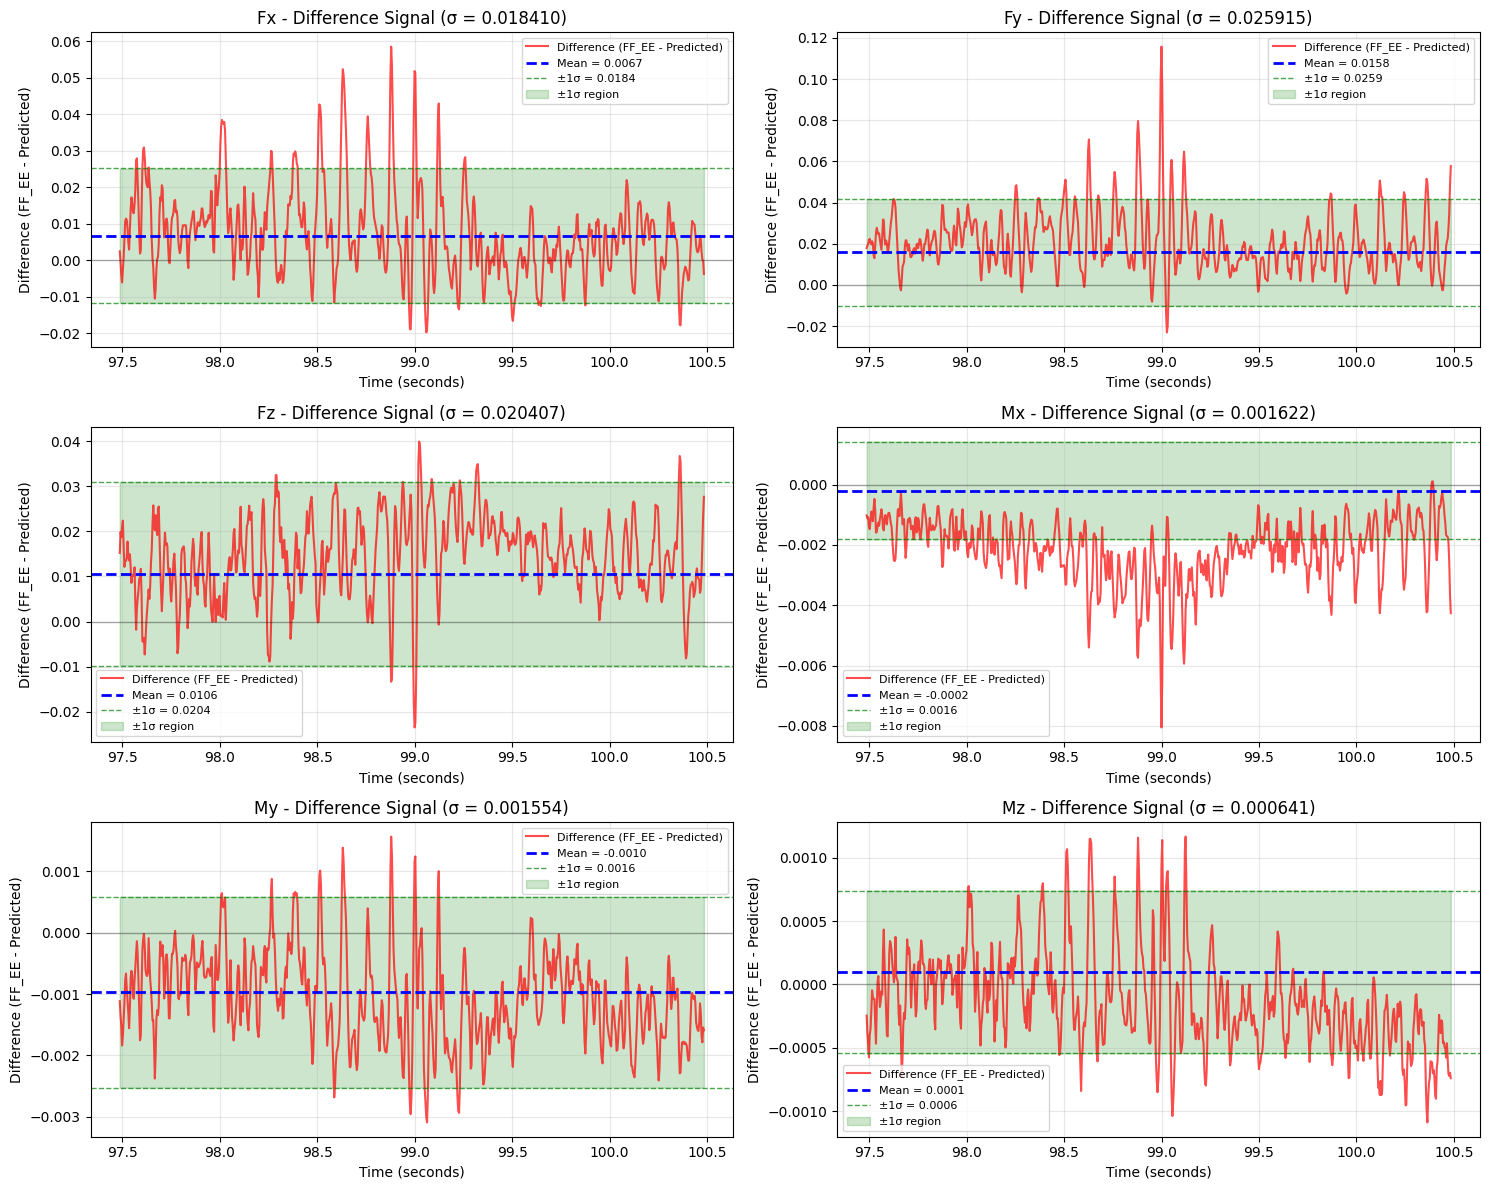

In [4]:
# Visualization: Difference signals over time
time_window_seconds = 3
time_window_samples = int(time_window_seconds * mean_freq)
start_idx = len(FF_EE) // 2

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

time_axis = np.arange(start_idx, start_idx + time_window_samples) / mean_freq

for dim in range(6):
    ax = axes[dim]
    
    # Calculate difference: x(t) - x^(t) = FF_EE - predicted_force
    diff_signal = FF_EE[:, dim] - predicted_force[:, dim]
    
    # Plot difference signal
    ax.plot(time_axis, diff_signal[start_idx:start_idx+time_window_samples], 
            'r-', linewidth=1.5, label='Difference (FF_EE - Predicted)', alpha=0.7)
    
    # Add mean and ±1σ lines
    mean_diff = std_dev_df.iloc[dim]['mean_difference']
    std_dev = std_dev_df.iloc[dim]['std_dev']
    
    ax.axhline(y=0, color='k', linestyle='-', linewidth=1, alpha=0.3)
    ax.axhline(y=mean_diff, color='b', linestyle='--', linewidth=2, label=f'Mean = {mean_diff:.4f}')
    ax.axhline(y=mean_diff + std_dev, color='g', linestyle='--', linewidth=1, alpha=0.7, label=f'±1σ = {std_dev:.4f}')
    ax.axhline(y=mean_diff - std_dev, color='g', linestyle='--', linewidth=1, alpha=0.7)
    ax.fill_between(time_axis, mean_diff - std_dev, mean_diff + std_dev, alpha=0.2, color='green', label='±1σ region')
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Difference (FF_EE - Predicted)')
    ax.set_title(f'{dim_names[dim]} - Difference Signal (σ = {std_dev:.6f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


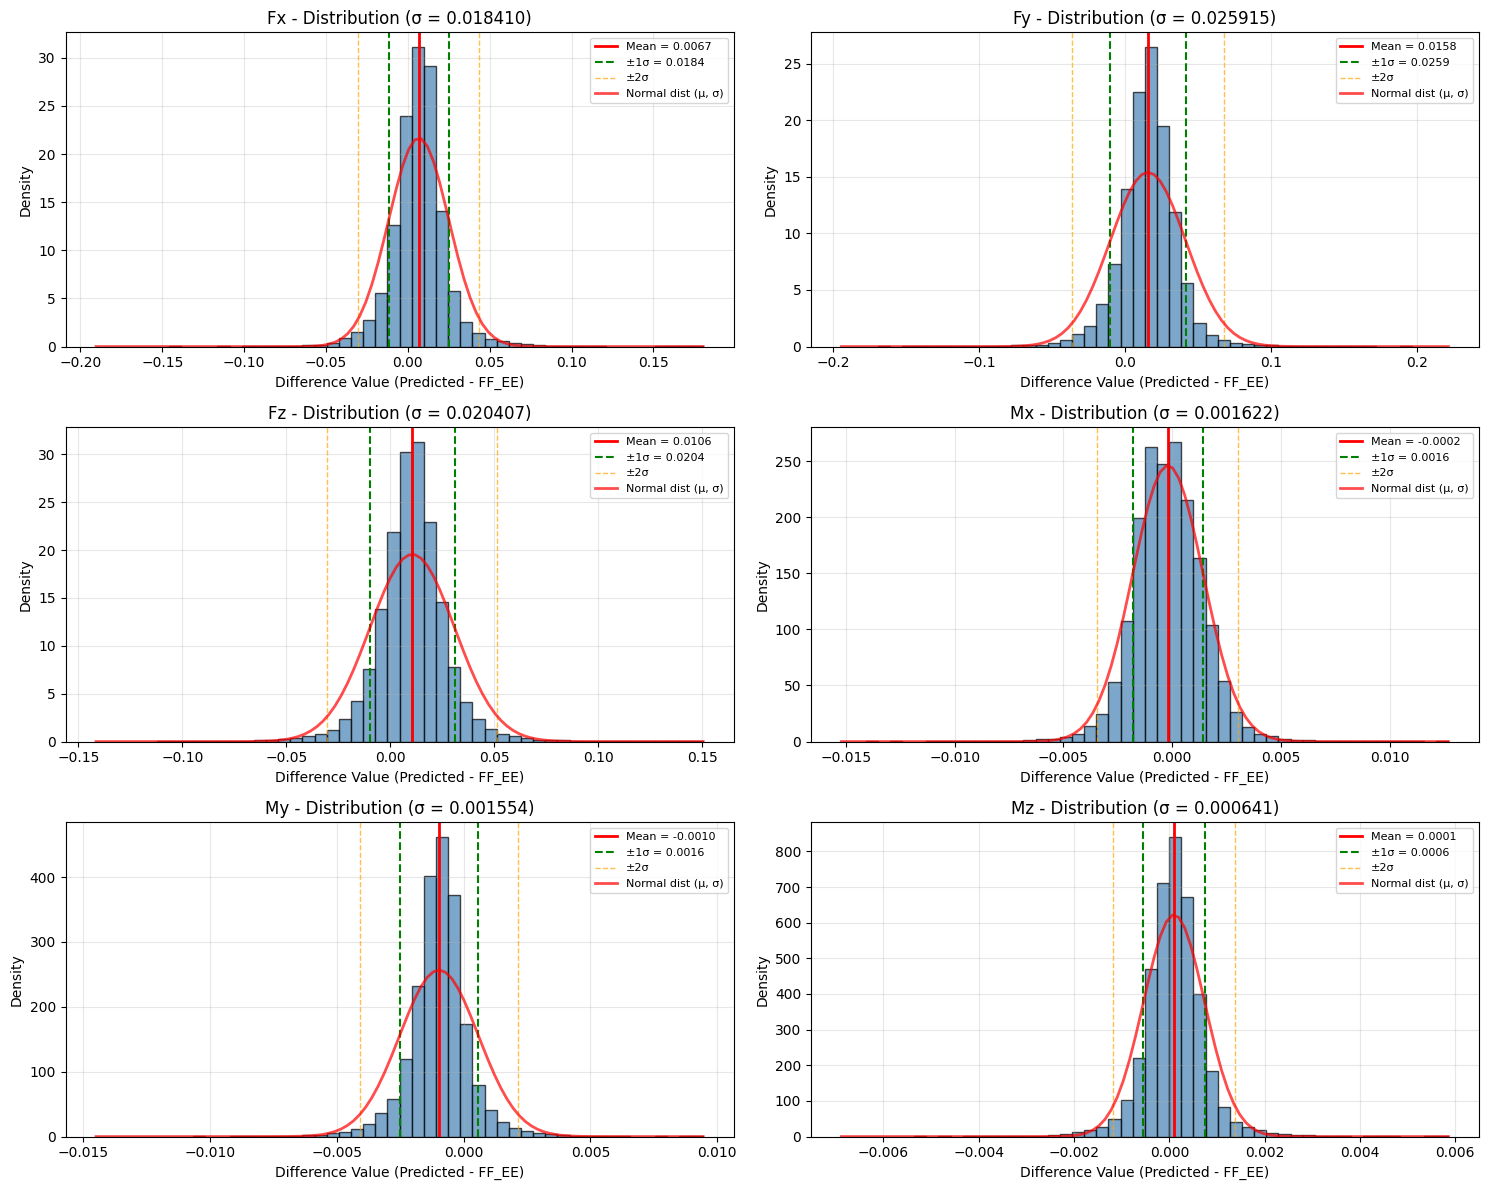

In [5]:
# Visualization: Histograms of differences with standard deviation
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Calculate difference: x(t) - x^(t) = FF_EE - predicted_force
    diff_dim = FF_EE[:, dim] - predicted_force[:, dim]
    mean_diff = std_dev_df.iloc[dim]['mean_difference']
    std_dev = std_dev_df.iloc[dim]['std_dev']
    
    # Histogram
    ax.hist(diff_dim, bins=50, alpha=0.7, color='steelblue', edgecolor='black', density=True)
    
    # Add vertical lines for mean and ±1σ, ±2σ, ±3σ
    ax.axvline(x=mean_diff, color='r', linestyle='-', linewidth=2, label=f'Mean = {mean_diff:.4f}')
    ax.axvline(x=mean_diff + std_dev, color='g', linestyle='--', linewidth=1.5, label=f'±1σ = {std_dev:.4f}')
    ax.axvline(x=mean_diff - std_dev, color='g', linestyle='--', linewidth=1.5)
    ax.axvline(x=mean_diff + 2*std_dev, color='orange', linestyle='--', linewidth=1, alpha=0.7, label=f'±2σ')
    ax.axvline(x=mean_diff - 2*std_dev, color='orange', linestyle='--', linewidth=1, alpha=0.7)
    
    # Overlay normal distribution for reference
    x_norm = np.linspace(diff_dim.min(), diff_dim.max(), 100)
    y_norm = (1 / (std_dev * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mean_diff) / std_dev)**2)
    ax.plot(x_norm, y_norm, 'r-', linewidth=2, label='Normal dist (μ, σ)', alpha=0.7)
    
    ax.set_xlabel('Difference Value (Predicted - FF_EE)')
    ax.set_ylabel('Density')
    ax.set_title(f'{dim_names[dim]} - Distribution (σ = {std_dev:.6f})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


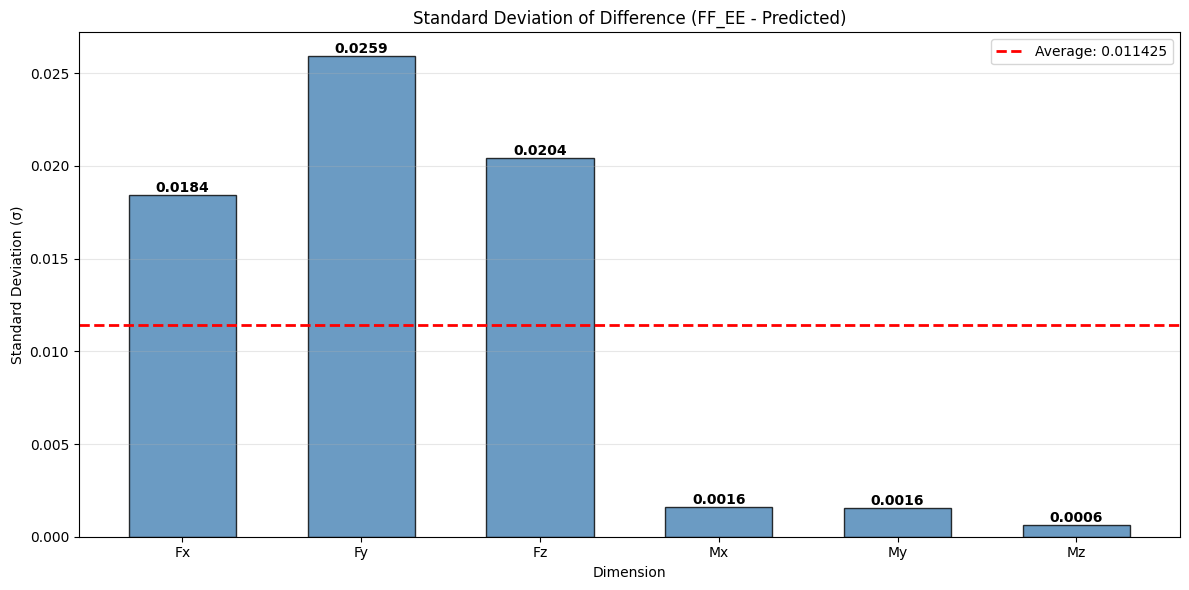

In [6]:
# Visualization: Bar chart comparing standard deviations
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(dim_names))
width = 0.6

bars = ax.bar(x, std_dev_df['std_dev'], width, alpha=0.8, color='steelblue', edgecolor='black')

ax.set_xlabel('Dimension')
ax.set_ylabel('Standard Deviation (σ)')
ax.set_title('Standard Deviation of Difference (FF_EE - Predicted)')
ax.set_xticks(x)
ax.set_xticklabels(dim_names)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{height:.4f}',
           ha='center', va='bottom', fontsize=10, fontweight='bold')

# Add average line
avg_std = std_dev_df['std_dev'].mean()
ax.axhline(y=avg_std, color='r', linestyle='--', linewidth=2, 
           label=f'Average: {avg_std:.6f}')
ax.legend()

plt.tight_layout()
plt.show()


In [7]:
# Export results to JSON
print("\n" + "=" * 80)
print("EXPORTING RESULTS")
print("=" * 80)

summary_report = {
    'method': 'Standard Deviation of Difference',
    'description': 'Standard deviation of the difference between filtered force (FF_EE) and predicted force',
    'formula': 'σ = √(1/N × Σ(x(t) - x^(t))²)',
    'where': {
        'x(t)': 'FF_EE(t) (filtered force)',
        'x^(t)': 'predicted_force(t) (predicted force)',
        'N': 'total number of samples'
    },
    'analysis_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'total_samples': len(data_points),
    'sampling_frequency_hz': float(mean_freq),
    'per_dimension_results': []
}

for dim in range(6):
    summary_report['per_dimension_results'].append({
        'dimension': dim_names[dim],
        'mean_difference': float(std_dev_df.iloc[dim]['mean_difference']),
        'standard_deviation': float(std_dev_df.iloc[dim]['std_dev']),
        'min_difference': float(std_dev_df.iloc[dim]['min_difference']),
        'max_difference': float(std_dev_df.iloc[dim]['max_difference']),
        'range': float(std_dev_df.iloc[dim]['range_difference'])
    })

# Add overall statistics
summary_report['overall_statistics'] = {
    'average_std_dev': float(std_dev_df['std_dev'].mean()),
    'min_std_dev': float(std_dev_df['std_dev'].min()),
    'min_std_dev_dimension': dim_names[std_dev_df['std_dev'].idxmin()],
    'max_std_dev': float(std_dev_df['std_dev'].max()),
    'max_std_dev_dimension': dim_names[std_dev_df['std_dev'].idxmax()]
}

# Save to JSON
output_json = Path('std_dev_analysis_summary.json')
with open(output_json, 'w') as f:
    json.dump(summary_report, f, indent=2)

print(f"✓ Results saved to {output_json}")
print(f"\nKey Findings:")
print(f"  Average standard deviation: {std_dev_df['std_dev'].mean():.6f}")
print(f"  Min std dev: {std_dev_df['std_dev'].min():.6f} ({dim_names[std_dev_df['std_dev'].idxmin()]})")
print(f"  Max std dev: {std_dev_df['std_dev'].max():.6f} ({dim_names[std_dev_df['std_dev'].idxmax()]})")



EXPORTING RESULTS
✓ Results saved to std_dev_analysis_summary.json

Key Findings:
  Average standard deviation: 0.011425
  Min std dev: 0.000641 (Mz)
  Max std dev: 0.025915 (Fy)
